# Expression prediction, context controls, and data confounds

Use **Python (scGPT inference)**. This notebook starts from files and has no dependency on earlier notebook variables.

**Audit correction:** the upstream generative code's custom cross-attention has identity projections, so it has no checkpoint tensors. Absence of `cross_attn` keys was not a mismatch. The accompanying CPU translation reproduces this computation and loads all 163 checkpoint tensors strictly. It is numerically checked against the authors' source using synthetic inputs, with a CPU replacement for the known-stream FlashAttention kernel. Your actual checkpoint and biological results must still be checked on Nibi.

**Question 1:** do the GEP and MVC heads use correct expression context? **Question 2:** do apparent performance differences track QC or cell-identity evidence? This notebook does not call CNAs or assign malignant labels.

Extract the supplied folder under `~/scgpt-cna/notebooks/` and keep `scgpt_session.py` alongside this notebook. See README for pinned source links and limitations.


In [1]:
from pathlib import Path
import sys, json, hashlib
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

candidates = [Path.cwd(), Path.cwd() / 'scgpt_session',
              Path.home() / 'scgpt-cna/notebooks/scgpt_session']
SESSION_DIR = next((p for p in candidates if (p / 'scgpt_session.py').is_file()), None)
assert SESSION_DIR is not None, 'Keep the notebook and scgpt_session.py together; set SESSION_DIR explicitly if needed.'
sys.path.insert(0, str(SESSION_DIR))
import scgpt_session as session

torch.set_num_threads(4)
print('Python:', sys.executable)
print('PyTorch:', torch.__version__)
print('Helper:', session.__file__)
assert '.venv-scgpt' in sys.executable, 'Select Python (scGPT inference).'


/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


Python: /home/akash1/scgpt-cna/.venv-scgpt/bin/python
PyTorch: 2.2.2+cpu
Helper: /home/akash1/scgpt-cna/notebooks/scgpt_session/scgpt_session.py


## 1. Paths and fixed experiment

The initial run uses four cells: two from each of the same selected CopyKAT groups. Change only `RUN_FULL` after inspecting it. A separate 25% mask experiment can be added later, but should not replace the fixed 15% result after seeing outcomes.


In [12]:
PROJECT_ROOT = Path('/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/benchmarking_spatial_scale')
SAMPLE_ID = 'C3N-00148-01'
SAMPLE_DIR = PROJECT_ROOT / 'GDC-data/C3N-00148' / SAMPLE_ID
BUNDLE_DIR = SAMPLE_DIR / 'single_cell/dbe28c52-cdbf-477e-a728-9a61fd4a8139'
DATA_DIR = BUNDLE_DIR / 'qc_filtered_bc_feature_matrix'
COPYKAT_PATH = BUNDLE_DIR / 'copykatOUT/_copykat_prediction.txt'
MODEL_DIR = Path.home() / 'scgpt-cna/models/whole-human'

SETTINGS = dict(seed=42, eval_per_group=16, ref_per_group=64,
                max_genes=1199, mask_fraction=0.15, repeats=2)
RUN_FULL = True
for path in [DATA_DIR / 'matrix.mtx', DATA_DIR / 'features.tsv',
             DATA_DIR / 'barcodes.tsv', COPYKAT_PATH, MODEL_DIR / 'best_model.pt']:
    assert path.is_file(), path


## 2. Data and QC evidence

Raw counts are preserved; sparse full matrices are not densified. CopyKAT labels are provisional. `not.defined` and missing cells are kept in the full object, although not selected for this benchmark.

Marker panels below are **descriptive expression summaries**, not validated cell labels. Scores cannot be compared across different panels as probabilities. Hypoxia markers are not proof of malignancy. Confirm lineage and tumour status with reviewed annotations or a suitable reference atlas.


In [3]:
adata = session.load_sample(DATA_DIR, COPYKAT_PATH)
obs, marker_coverage = session.qc_and_markers(adata)
print(adata)
display(obs['copykat_prediction'].fillna('missing').value_counts())
display(obs.groupby('copykat_prediction', dropna=False)[
    ['total_counts', 'n_genes_detected', 'pct_counts_mt', 'fraction_detected_genes_count1']
].agg(['count', 'median', 'min', 'max']))
display(marker_coverage)

metadata_path = PROJECT_ROOT / 'metadata/sample_md.tsv'
if metadata_path.is_file():
    md = pd.read_csv(metadata_path, sep='\t', dtype=str, keep_default_na=False)
    display(md.loc[md['sample_id'].eq(SAMPLE_ID),
        ['sample_id', 'case_id', 'diagnoses.0.primary_diagnosis', 'primary_site', 'wgd_status']])


AnnData object with n_obs × n_vars = 7598 × 60660
    obs: 'copykat_prediction'
    var: 'gene_id', 'gene_symbol'
    layers: 'counts'


copykat_prediction
aneuploid      4106
diploid        2100
not.defined    1378
missing          14
Name: count, dtype: int64

total_counts                     n_genes_detected          \
                          count  median  min    max            count  median   
copykat_prediction                                                             
aneuploid                  4106  3367.0  778  19863             4106  1818.0   
diploid                    2100  2916.0  647  24279             2100  1590.0   
not.defined                1378  1456.0  500  14529             1378   876.5   
NaN                          14  1556.5  954   2833               14   136.5   

                              pct_counts_mt                                  \
                    min   max         count     median       min        max   
copykat_prediction                                                            
aneuploid           596  5513          4106   0.128308  0.000000  57.389912   
diploid             473  6980          2100   2.662726  0.000000  60.016090   
not.defined         209  4243          1378   1.231535  0.000000  91.551988   
NaN                  64   169            14  91.582414  0.949598  98.041431   

                   fraction_detected_genes_count1                      \
                                            count    median       min   
copykat_prediction                                                      
aneuploid                                    4106  0.739005  0.434359   
diploid                                      2100  0.730650  0.448138   
not.defined                                  1378  0.813706  0.474193   
NaN                                            14  0.799107  0.731343   

                              
                         max  
copykat_prediction            
aneuploid           0.894554  
diploid             0.886740  
not.defined         0.931174  
NaN                 0.846154

,panel,present,n_present_symbols,n_requested
0,T_cell,"CD3D, CD3E, TRAC",3,3
1,B_cell,"CD79A, CD79B, MS4A1",3,3
2,myeloid,"FCER1G, LST1, LYZ, TYROBP",4,4
3,endothelial,"EMCN, PECAM1, VWF",3,3
4,fibroblast,"COL1A1, COL1A2, DCN, LUM",4,4
5,epithelial,"EPCAM, KRT18, KRT19, KRT8",4,4
6,proximal_tubule,"CUBN, LRP2, SLC34A1",3,3
7,renal_hypoxia,"CA9, NDUFA4L2",2,2


,sample_id,case_id,diagnoses.0.primary_diagnosis,primary_site,wgd_status
11,C3N-00148-01,C3N-00148,"Renal cell carcinoma, NOS",Kidney,WGD+


In [4]:
# Compare groups WITHIN each marker panel, not between different panels.
marker_cols = [c for c in obs if c.startswith('marker_')]
display(obs.groupby('copykat_prediction')[marker_cols].median())

# Optional after Zaid's table arrives. Inspect its actual headers first.
# The function joins on explicit sample ID + barcode and checks duplicate keys.
MANUAL_LABELS = None  # Path('/path/to/table.xlsx')
if MANUAL_LABELS is not None:
    obs = session.load_manual_labels(obs, MANUAL_LABELS, SAMPLE_ID,
                                    sample_col='sample_id', barcode_col='barcode')
    display(obs.filter(regex='^manual_').head())


,marker_T_cell,marker_B_cell,marker_myeloid,marker_endothelial,marker_fibroblast,marker_epithelial,marker_proximal_tubule,marker_renal_hypoxia
copykat_prediction,,,,,,,,
aneuploid,0.0,0.0,0.0,0.0,0.0,0.0,0.705363,0.0
diploid,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
not.defined,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0


## 3. Strict checkpoint loading and model feature alignment

Both heads are loaded: GEP is the generative unknown-gene decoder; MVC uses the known-only CLS summary and query gene identity. No target expression enters either query. This notebook intentionally supports this checkpoint's postnorm, continuous, binned architecture with no padding or batch correction.


In [5]:
model, vocab, config = session.load_model(MODEL_DIR)
display(pd.Series({k: config[k] for k in [
    'embsize', 'nlayers', 'nheads', 'n_bins', 'max_seq_len',
    'mask_ratio', 'USE_GENERATIVE_TRAINING', 'MVC'
]}))
assert len(model.state_dict()) == 163
assert SETTINGS['max_genes'] + 1 <= config['max_seq_len']
assert config.get('mask_value') == -1 and config.get('pad_value') == -2
X, gene_ids, gene_info = session.prepare_expression(adata, vocab)


Strict load: 163 checkpoint tensors; no omitted tensors.


embsize                                  512
nlayers                                   12
nheads                                     8
n_bins                                    51
max_seq_len                             1200
mask_ratio                 [0.25, 0.5, 0.75]
USE_GENERATIVE_TRAINING                 True
MVC                                     True
dtype: object

Model features: 39,800; first occurrence retained for duplicate symbols.


## 4. Fixed evaluation/reference split

All selected cells have 1,000–3,000 detected features in the original matrix. This coarse restriction does not eliminate depth, mitochondrial, or cell-type confounding. Reference cells never overlap with evaluated cells.

Targets are known to be expressed. We are not testing zeros, deletion-related absence, or whole-transcriptome imputation. Reference gene means are conditional on nonzero expression. The additional group-specific gene mean is a stronger comparator, but uses provisional CopyKAT group information.


In [13]:
evaluation, reference = session.select_cells(obs, SETTINGS)
if RUN_FULL:
    run_cells = evaluation
else:
    run_cells = np.concatenate([
        evaluation[obs.iloc[evaluation]['copykat_prediction'].eq(g).to_numpy()][:2]
        for g in ['diploid', 'aneuploid']
    ])
print('Selected evaluation/reference:', len(evaluation), len(reference))
print('This run:', len(run_cells), 'cells')
display(obs.iloc[run_cells][['copykat_prediction', 'total_counts',
                            'n_genes_detected', 'pct_counts_mt']])
baselines = session.reference_baselines(X, obs, reference, SETTINGS['seed'], config['n_bins'])


Selected evaluation/reference: 32 128
This run: 32 cells


,copykat_prediction,total_counts,n_genes_detected,pct_counts_mt
barcode,,,,
TCCTCGAGTGGGATTG-1,diploid,2383,1266,21.275703
TCCAGAATCGCAACAT-1,diploid,2947,1675,2.239566
GAACACTTCCCAGGCA-1,diploid,2647,1432,10.691349
TACGGGCGTCCCTCAT-1,diploid,1755,1178,0.683761
TTCAGGATCAGCTCTC-1,diploid,3061,1773,0.784057
GAGTCATTCGGTAGAG-1,diploid,2293,1172,27.736590
TACACCCAGGCGTCCT-1,diploid,4616,2111,24.718371
CCGTTCATCGTTACCC-1,diploid,2573,1353,14.963078
TCAGTCCCATGAGGGT-1,diploid,2789,1558,4.302617


## 5. Paired context experiment, same targets for both heads

Known and query genes are separated. Unknown inputs use the learned flag and no expression value. Each unknown attends to known genes and itself, never other unknown genes. Known genes cannot attend to unknown genes. The implementation preserves the authors' projection-free unknown-stream attention.

Every mask is evaluated with **correct context** and **visible values shuffled among the same known genes**; CLS is preserved. This holds input values, identities, and targets fixed, but shuffling creates an artificial distribution shift.

Primary bins use visible selected values only. This avoids hidden-value influence on bin boundaries, but differs from the pretraining collator's full-cell binning. Both heads receive the same bins. Target scoring integrates over randomized bin-tie support instead of scoring a single arbitrary bin draw. Expected MSE = error against tie mean + tie variance. Reference-cell bins use complete reference profiles, an approximation retained from the preceding experiment.


In [14]:
results = session.benchmark(model, vocab, X, gene_ids, gene_info, obs,
                            run_cells, baselines, SETTINGS)
display(results['summary'])
paired = session.paired_context_results(results['per_cell'])
paired_columns = [c for c in paired if 'minus' in c]
display(paired.groupby(level='copykat_group')[paired_columns].agg(['mean', 'median', 'min', 'max']))
print('Negative correct_minus_shuffled = correct context helped.')
print('Negative minus_gene_mean = model beat pooled gene mean.')


Completed 1/32 cells
Completed 2/32 cells
Completed 3/32 cells
Completed 4/32 cells
Completed 5/32 cells
Completed 6/32 cells
Completed 7/32 cells
Completed 8/32 cells
Completed 9/32 cells
Completed 10/32 cells
Completed 11/32 cells
Completed 12/32 cells
Completed 13/32 cells
Completed 14/32 cells
Completed 15/32 cells
Completed 16/32 cells
Completed 17/32 cells
Completed 18/32 cells
Completed 19/32 cells
Completed 20/32 cells
Completed 21/32 cells
Completed 22/32 cells
Completed 23/32 cells
Completed 24/32 cells
Completed 25/32 cells
Completed 26/32 cells
Completed 27/32 cells
Completed 28/32 cells
Completed 29/32 cells
Completed 30/32 cells
Completed 31/32 cells
Completed 32/32 cells


n_cells  mean_expected_MSE  \
copykat_group method                                        
aneuploid     GEP_correct           16         191.674529   
              GEP_shuffled          16         197.583846   
              MVC_correct           16         192.593434   
              MVC_shuffled          16         198.681564   
              constant              16         207.029267   
              gene_mean             16         192.308285   
              group_gene_mean       16         198.720928   
diploid       GEP_correct           16         187.924135   
              GEP_shuffled          16         197.470379   
              MVC_correct           16         188.396925   
              MVC_shuffled          16         197.596828   
              constant              16         205.574530   
              gene_mean             16         199.790434   
              group_gene_mean       16         205.750658   

                               median_expected_MSE  mean_prediction_std  
copykat_group method                                                     
aneuploid     GEP_correct               193.359711         4.496348e+00  
              GEP_shuffled              197.570689         3.017945e+00  
              MVC_correct               193.142716         3.968271e+00  
              MVC_shuffled              197.185257         2.728345e+00  
              constant                  205.320529         3.552714e-15  
              gene_mean                 191.425046         6.315276e+00  
              group_gene_mean           195.792669         7.033114e+00  
diploid       GEP_correct               189.215246         4.919746e+00  
              GEP_shuffled              196.822533         3.046672e+00  
              MVC_correct               190.582877         4.768829e+00  
              MVC_shuffled              196.501559         3.047415e+00  
              constant                  205.101718         2.886580e-15  
              gene_mean                 199.473956         5.879914e+00  
              group_gene_mean           205.000796         6.885605e+00

method        MVC_correct_minus_shuffled                                 \
                                    mean    median        min       max   
copykat_group                                                             
aneuploid                      -6.088130 -6.126209 -13.023995 -1.433866   
diploid                        -9.199903 -6.934974 -25.643986 -0.700485   

method        MVC_minus_gene_mean                                  \
                             mean    median        min        max   
copykat_group                                                       
aneuploid                0.285149  2.755015 -15.047581  15.019656   
diploid                -11.393509 -8.382901 -34.593229   0.879529   

method        GEP_correct_minus_shuffled                                 \
                                    mean    median        min       max   
copykat_group                                                             
aneuploid                      -5.909317 -5.944860 -13.747922 -0.532419   
diploid                        -9.546243 -8.237731 -26.837072 -1.465514   

method        GEP_minus_gene_mean                                  
                             mean    median        min        max  
copykat_group                                                      
aneuploid               -0.633755  0.596598 -17.155919  17.066334  
diploid                -11.866299 -9.703561 -32.112080  -0.059545

Negative correct_minus_shuffled = correct context helped.
Negative minus_gene_mean = model beat pooled gene mean.


## 6. Prediction and context plots

The x-axis is the expected bin for a tied measurement, not a random target draw or raw RNA count. A wider prediction range alone is not improvement; use paired error scores. Four cells are only a smoke test.


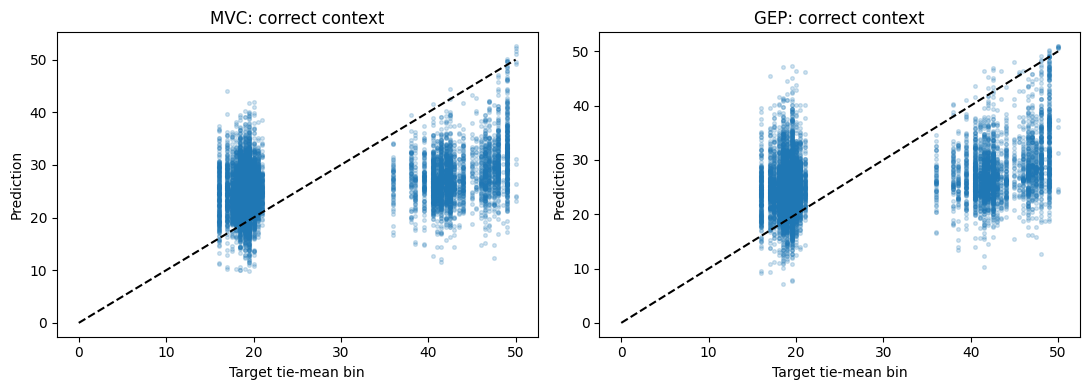

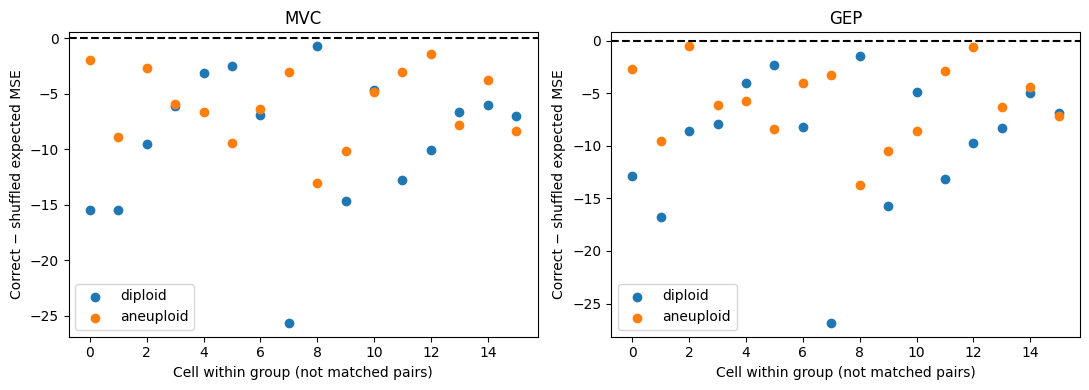

In [15]:
p = results['predictions']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, route in zip(axes, ['MVC', 'GEP']):
    ax.scatter(p['target_tie_mean'], p[route + '_correct'], s=7, alpha=.2)
    ax.plot([0, 50], [0, 50], 'k--')
    ax.set(xlabel='Target tie-mean bin', ylabel='Prediction', title=route + ': correct context')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, route in zip(axes, ['MVC', 'GEP']):
    col = route + '_correct_minus_shuffled'
    for group, color in [('diploid', 'tab:blue'), ('aneuploid', 'tab:orange')]:
        vals = paired.xs(group, level='copykat_group')[col].to_numpy()
        ax.scatter(np.arange(len(vals)), vals, label=group, color=color)
    ax.axhline(0, color='black', linestyle='--')
    ax.set(xlabel='Cell within group (not matched pairs)', ylabel='Correct − shuffled expected MSE', title=route)
    ax.legend()
plt.tight_layout()
plt.show()


## 7. Data-related explanations

Inspect associations within groups; pooled differences can reflect composition. These correlations are exploratory, with no causal interpretation or patient-level significance claim. No automatic quality filtering or cell-type assignment is performed. A mitochondrial association might reflect quality or biology. Marker evidence should be checked with the lab.


,group,method,feature,n_cells,spearman_rho
0,aneuploid,GEP_correct,total_counts,16,-0.241176
1,aneuploid,GEP_correct,n_genes_detected,16,-0.250184
2,aneuploid,GEP_correct,pct_counts_mt,16,0.020588
3,aneuploid,GEP_correct,fraction_detected_genes_count1,16,0.411765
4,aneuploid,GEP_correct,marker_T_cell,16,0.420084
...,...,...,...,...,...
67,diploid,gene_mean,marker_endothelial,16,0.012944
68,diploid,gene_mean,marker_fibroblast,16,0.276129
69,diploid,gene_mean,marker_epithelial,16,-0.140028
70,diploid,gene_mean,marker_proximal_tubule,16,NaN


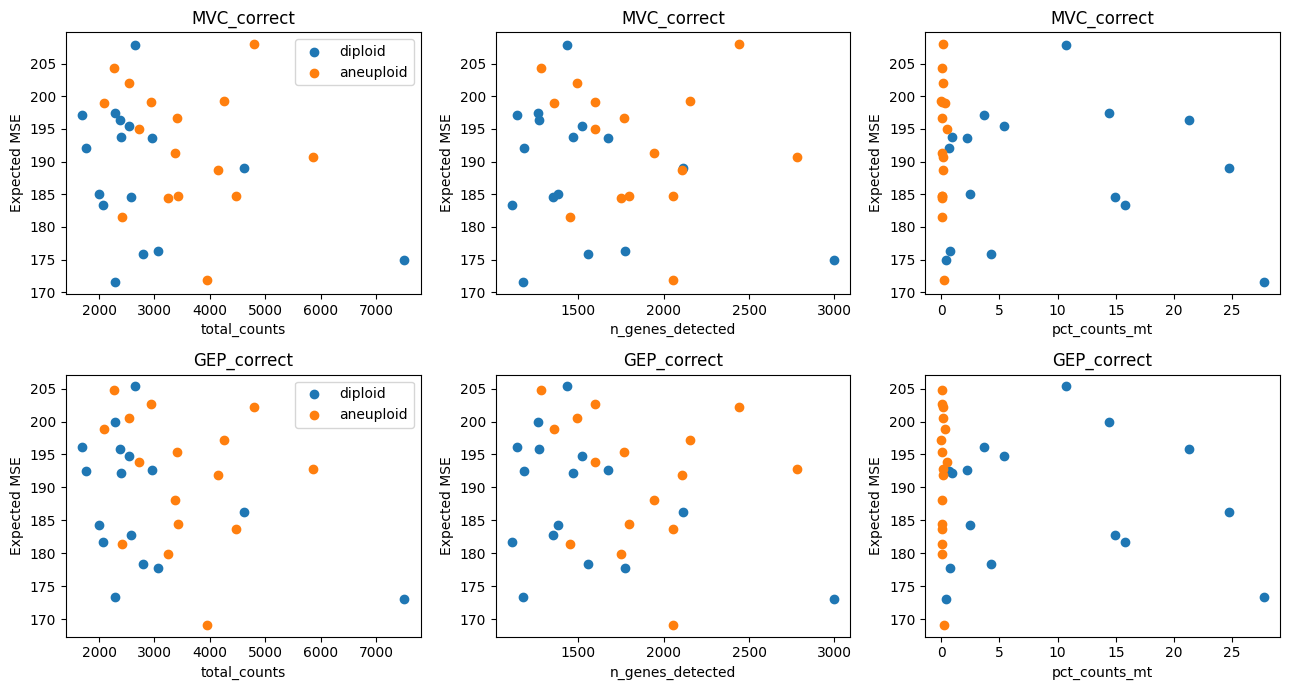

In [16]:
associations = session.qc_associations(results['per_cell'])
display(associations)

cell = results['per_cell']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for row, route in enumerate(['MVC_correct', 'GEP_correct']):
    frame = cell.loc[cell['method'].eq(route)]
    for ax, feature in zip(axes[row], ['total_counts', 'n_genes_detected', 'pct_counts_mt']):
        for group, color in [('diploid', 'tab:blue'), ('aneuploid', 'tab:orange')]:
            subset = frame.loc[frame['copykat_group'].eq(group)]
            ax.scatter(subset[feature], subset['expected_MSE'], label=group, color=color)
        ax.set(xlabel=feature, ylabel='Expected MSE', title=route)
    axes[row, 0].legend()
plt.tight_layout()
plt.show()

manual_cols = [c for c in cell if c.startswith('manual_')]
if manual_cols:
    print('Manual fields available:', manual_cols)
    print('Inspect labels and provenance before aggregating errors by a chosen cell-type field.')


## 8. Save a reproducible local run

This creates a new results directory on Nibi and leaves the source dataset unchanged. Cell identifiers and expression-derived results stay there. Record the smoke run even if results are unpromising. Set `RUN_FULL=True` above and rerun from the split cell onward only after the smoke checks pass; do not change the mask or split to select favourable outcomes.


In [10]:
SAVE_OUTPUTS = True
if SAVE_OUTPUTS:
    tag = 'full' if RUN_FULL else 'smoke'
    out_dir = Path.home() / 'scgpt-cna/results' / (
        'expression_' + tag + '_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
    out_dir.mkdir(parents=True, exist_ok=False)
    results['summary'].to_csv(out_dir / 'summary.csv')
    results['per_cell'].to_csv(out_dir / 'per_cell.csv', index=False)
    results['predictions'].to_csv(out_dir / 'predictions.csv', index=False)
    results['targets'].to_csv(out_dir / 'target_ties.csv', index=False)
    associations.to_csv(out_dir / 'qc_associations.csv', index=False)
    paired.to_csv(out_dir / 'paired_comparisons.csv')
    marker_coverage.to_csv(out_dir / 'marker_coverage.csv', index=False)
    manifest = session.run_manifest(MODEL_DIR, SETTINGS)
    manifest.update(sample_id=SAMPLE_ID, run_full=RUN_FULL,
        evaluation_barcodes=obs.index[evaluation].tolist(),
        run_barcodes=obs.index[run_cells].tolist(),
        reference_barcodes=obs.index[reference].tolist(),
        helper_sha256=hashlib.sha256((SESSION_DIR / 'scgpt_session.py').read_bytes()).hexdigest())
    (out_dir / 'run_manifest.json').write_text(json.dumps(manifest, indent=2))
    print('Saved:', out_dir)


Saved: /home/akash1/scgpt-cna/results/expression_smoke_20261016_134436_229908


## What to share next

Share the strict-load result (expect 163 tensors), summary table, paired context comparisons, and the QC plots. Describe marker patterns as preliminary evidence, not labels. We can then decide whether to expand annotation/reference mapping, adjust context selection or preprocessing in a separately documented experiment, or move to regional/WGS evaluation after assembly/sample verification.

The important question is not simply whether aneuploid cells have larger error. We need to know whether correct context adds predictive information, whether the gain survives stronger baselines, and whether remaining errors track biological or technical confounders.


In [11]:
marker_cols = [c for c in obs.columns if c.startswith("marker_")]

marker_detection = (
    obs.assign(group=obs["copykat_prediction"].fillna("missing"))
    .groupby("group")[marker_cols]
    .agg(lambda s: 100 * s.gt(0).mean())
)

display(marker_detection.round(1))

,marker_T_cell,marker_B_cell,marker_myeloid,marker_endothelial,marker_fibroblast,marker_epithelial,marker_proximal_tubule,marker_renal_hypoxia
group,,,,,,,,
aneuploid,2.6,0.4,12.5,7.5,6.1,29.5,79.1,42.0
diploid,27.2,7.5,39.8,41.2,16.8,10.4,10.9,16.3
missing,7.1,7.1,0.0,0.0,0.0,14.3,14.3,7.1
not.defined,23.1,5.4,16.3,14.6,9.4,9.7,24.3,16.5
